# B2B SaaS Trial Activation: Finding the Real “Aha Moment”

**Author:** Yelyzaveta Zakharova, Product Analyst
**Data:** fully simulated data of a fictional team task-management tool ("Northdesk"). No real company data is used.

**Business question.** Only ~1 in 5 free trials converts to paid. Onboarding currently pushes new workspaces to **create 3 projects**.
Is that the right activation goal, or is there an early action that actually drives conversion, and how much is moving it worth?

**Data.** `trials.csv`: 12,000 14-day trials (Apr–Sep 2025): company size, channel, industry, actions in the **first 3 days**, conversion and starting MRR.

**Approach.** Candidate actions in days 0–2 (so the action comes before the outcome) → raw lift → lift adjusted for company size, channel, industry and the other actions →
threshold → timing → opportunity sizing, with a clear statement of what observational data can and can't prove.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("data/trials.csv")
df["inv_cat"] = pd.cut(df.invites_d0_2, [-1, 0, 1, 100], labels=["0", "1", "2+"]).astype(str)
df["inv2"] = (df.invites_d0_2 >= 2).astype(int); df["proj3"] = (df.projects_d0_2 >= 3).astype(int)
df["team"] = (df.company_size != "1").astype(int)
print(f"{len(df):,} trials, conversion {df.converted.mean():.1%}")
df.groupby("company_size").agg(trials=("converted", "size"), conversion=("converted", "mean"), mrr=("starting_mrr_usd", "mean")).round(3)

12,000 trials, conversion 19.4%


,trials,conversion,mrr
company_size,,,
1,2578,0.104,1.247
100+,816,0.223,27.882
2-5,3602,0.184,8.115
21-100,1872,0.249,30.660
6-20,3132,0.241,21.142


## 1. Candidate “aha” actions: raw lift

In [2]:
CAND = {"Invited 2+ teammates": "inv2", "Created 3+ projects": "proj3",
        "Connected an integration": "integration_d0_2", "Used the mobile app": "mobile_app_d0_2"}
raw = []
for lab, c in CAND.items():
    d = df[df.team == 1] if c == "inv2" else df
    a, b = d[d[c] == 1].converted.mean(), d[d[c] == 0].converted.mean()
    raw.append(dict(action=lab, share_doing=d[c].mean(), conv_with=a, conv_without=b, raw_lift_pp=(a - b) * 100))
raw = pd.DataFrame(raw).set_index("action"); raw.round(3)

,share_doing,conv_with,conv_without,raw_lift_pp
action,,,,
Invited 2+ teammates,0.544,0.322,0.097,22.523
Created 3+ projects,0.223,0.363,0.146,21.718
Connected an integration,0.225,0.348,0.150,19.773
Used the mobile app,0.303,0.277,0.159,11.811


Every candidate looks strong on raw numbers, including the 3-projects goal. But motivated teams do *everything* more, so raw lift mixes the action's effect with who chooses to do it.

## 2. Adjusted effect
Logistic regression of conversion on all four actions together plus company size, channel, industry and two **signals of intent captured at signup**
(the signup survey answer “how far along are you?” and whether they visited the pricing page before signing up), then **g-computation**:
predict every workspace's conversion with the action switched on and off and average the difference (average marginal effect, in percentage points).
Bootstrap CIs (200 resamples). Invites are compared 2+ vs 0, among workspaces with more than one person.

In [3]:
FORM = ("converted ~ C(inv_cat) + proj3 + integration_d0_2 + mobile_app_d0_2 + C(company_size) + C(channel) + C(industry)"
        " + C(signup_stage) + visited_pricing_before_signup")

def ames(d):
    m = smf.logit(FORM, data=d).fit(disp=0)
    out = {}
    t = d[d.team == 1]
    out["Invited 2+ teammates"] = (m.predict(t.assign(inv_cat="2+")) - m.predict(t.assign(inv_cat="0"))).mean()
    for lab, c in list(CAND.items())[1:]:
        out[lab] = (m.predict(d.assign(**{c: 1})) - m.predict(d.assign(**{c: 0}))).mean()
    return pd.Series(out)

est = ames(df)
rng = np.random.default_rng(0)
boot = pd.DataFrame([ames(df.iloc[rng.integers(0, len(df), len(df))]) for _ in range(200)])
adj = pd.DataFrame({"adjusted_pp": est * 100, "lo": boot.quantile(.025) * 100, "hi": boot.quantile(.975) * 100})
raw_inv0 = (df[(df.team == 1) & (df.inv_cat == "2+")].converted.mean() - df[(df.team == 1) & (df.inv_cat == "0")].converted.mean()) * 100
eff = raw[["raw_lift_pp"]].join(adj); eff.loc["Invited 2+ teammates", "raw_lift_pp"] = raw_inv0
eff.round(2)

,raw_lift_pp,adjusted_pp,lo,hi
action,,,,
Invited 2+ teammates,25.56,16.24,14.08,18.31
Created 3+ projects,21.72,7.34,5.90,8.84
Connected an integration,19.77,9.50,7.90,10.88
Used the mobile app,11.81,2.06,0.76,3.88


After adjustment the picture changes:
- **Inviting 2+ teammates** stays the largest effect by far.
- **Integration** keeps a moderate one.
- **Creating 3+ projects** loses two thirds of its raw lift, and **using the mobile app** almost all of it: they are mostly signs of a motivated team, not causes of conversion.

The onboarding is pushing a weak action.

## 3. Threshold: how many invites?

In [4]:
t = df[df.team == 1].copy(); t["inv_n"] = np.minimum(t.invites_d0_2, 4).astype(str)
thr = t.groupby("inv_n").agg(trials=("converted", "size"), conversion=("converted", "mean"))
thr["share"] = thr.trials / thr.trials.sum()
F2 = FORM.replace("C(inv_cat)", "C(inv_n)")
m2 = smf.logit(F2, data=t).fit(disp=0)
thr["adjusted"] = [m2.predict(t.assign(inv_n=k)).mean() for k in thr.index]
bt = []
for b in range(200):
    tb = t.iloc[rng.integers(0, len(t), len(t))]; mb = smf.logit(F2, data=tb).fit(disp=0)
    bt.append([mb.predict(tb.assign(inv_n=k)).mean() for k in thr.index])
bt = np.array(bt); thr["adj_lo"] = np.percentile(bt, 2.5, 0); thr["adj_hi"] = np.percentile(bt, 97.5, 0)
thr["raw_step_pp"] = thr.conversion.diff() * 100; thr["adj_step_pp"] = thr.adjusted.diff() * 100
thr.round(3)

,trials,conversion,share,adjusted,adj_lo,adj_hi,raw_step_pp,adj_step_pp
inv_n,,,,,,,,
0,2035,0.066,0.216,0.102,0.085,0.119,NaN,NaN
1,2258,0.124,0.240,0.148,0.131,0.164,5.766,4.604
2,1739,0.242,0.185,0.245,0.228,0.267,11.809,9.652
3,1285,0.283,0.136,0.258,0.236,0.280,4.118,1.305
4,2105,0.411,0.223,0.308,0.287,0.328,12.813,5.006


Raw conversion keeps rising with every invite, because bigger, more motivated teams invite more people.
After adjustment the curve has a clear shape: the biggest step is from **1 to 2 invites**, and gains flatten after that. Two teammates is when the tool becomes a shared workspace instead of a personal list.

## 4. Timing: does it have to happen early?

In [5]:
inv = df[(df.team == 1) & (df.first_invite_day >= 0)]
timing = inv.groupby(inv.first_invite_day <= 2).converted.mean().rename({True: "first invite in days 0–2", False: "first invite in days 3–13"})
cum = pd.DataFrame({k: [((g.first_invite_day >= 0) & (g.first_invite_day <= dd)).mean() for dd in range(14)]
                    for k, g in [("Converted", df[(df.team == 1) & (df.converted == 1)]), ("Did not convert", df[(df.team == 1) & (df.converted == 0)])]})
display(timing.round(3))
print(f"Of converted team workspaces, {cum.loc[2, 'Converted']:.0%} had invited someone by day 2 (vs {cum.loc[2, 'Did not convert']:.0%} of the rest)")

first_invite_day
first invite in days 3–13    0.075
first invite in days 0–2     0.261
Name: converted, dtype: float64

Of converted team workspaces, 93% had invited someone by day 2 (vs 74% of the rest)


## 5. Solo workspaces can't invite: what is their activation?

In [6]:
solo = df[df.team == 0]
solo_tbl = pd.DataFrame({lab: [solo[solo[c] == 1].converted.mean(), solo[solo[c] == 0].converted.mean(), solo[c].mean()]
                         for lab, c in list(CAND.items())[1:]}, index=["conv_with", "conv_without", "share_doing"]).T
solo_tbl.round(3)

,conv_with,conv_without,share_doing
Created 3+ projects,0.199,0.077,0.220
Connected an integration,0.188,0.083,0.198
Used the mobile app,0.155,0.082,0.303


## 6. What is it worth?
Scenario: an onboarding change (an invite step in setup, plus a day-1 reminder) moves **25%** of team workspaces that invite fewer than 2 people in days 0–2 to 2+.
The adjusted effect is used, not the raw one, and it is treated as an **upper bound** because observational data can't rule out hidden motivation.

In [7]:
months = 6
elig = df[(df.team == 1) & (df.invites_d0_2 < 2)]
ame_elig = (smf.logit(FORM, data=df).fit(disp=0).predict(elig.assign(inv_cat="2+")) -
            smf.logit(FORM, data=df).fit(disp=0).predict(elig)).mean()
mrr_new = df[(df.converted == 1) & (df.inv2 == 1)].starting_mrr_usd.mean()
moved = len(elig) / months * 0.25
extra = moved * ame_elig
opp = dict(eligible_per_month=len(elig) / months, moved_per_month=moved, ame_eligible_pp=ame_elig * 100,
           extra_customers_per_month=extra, mrr_per_customer=mrr_new, new_mrr_per_month=extra * mrr_new,
           arr_after_12_months=extra * mrr_new * 12)
pd.Series(opp).round(1)

eligible_per_month             715.5
moved_per_month                178.9
ame_eligible_pp                 11.2
extra_customers_per_month       20.1
mrr_per_customer                95.4
new_mrr_per_month             1914.6
arr_after_12_months          22975.7
dtype: float64

## 7. Sanity check against the simulation
On simulated data the true causal effects are known, so the observational estimates can be scored. With real data this is what an A/B test is for.

In [8]:
truth = json.load(open("data/_true_effects_for_validation_only.json"))
check = pd.DataFrame({"raw_pp": eff.raw_lift_pp, "adjusted_pp": eff.adjusted_pp,
                      "true_pp": [truth["invites2_vs_0"] * 100, truth["projects3"] * 100, truth["integration"] * 100, truth["mobile"] * 100]},
                     index=eff.index)
check.round(1)

,raw_pp,adjusted_pp,true_pp
action,,,
Invited 2+ teammates,25.6,16.2,12.6
Created 3+ projects,21.7,7.3,1.8
Connected an integration,19.8,9.5,6.1
Used the mobile app,11.8,2.1,0.0


Adjustment moves every estimate much closer to the truth and gets the **ranking** right, but it still overstates effects, because motivation isn't fully observed.
That's why the recommendation is to ship the invite step as an A/B test, with the sizing above as an upper bound.

## 8. Recommendation
1. **Change the activation goal** from “3 projects” to “2+ teammates invited in the first 3 days” for team workspaces.
2. **Onboarding:** make inviting part of setup (not a later prompt) and send a day-1 reminder to workspaces with fewer than 2 invites.
3. **Solo workspaces:** use “integration connected” as their activation goal.
4. **Validate** with an A/B test: primary metric trial-to-paid conversion, secondary invites in days 0–2.

## Charts

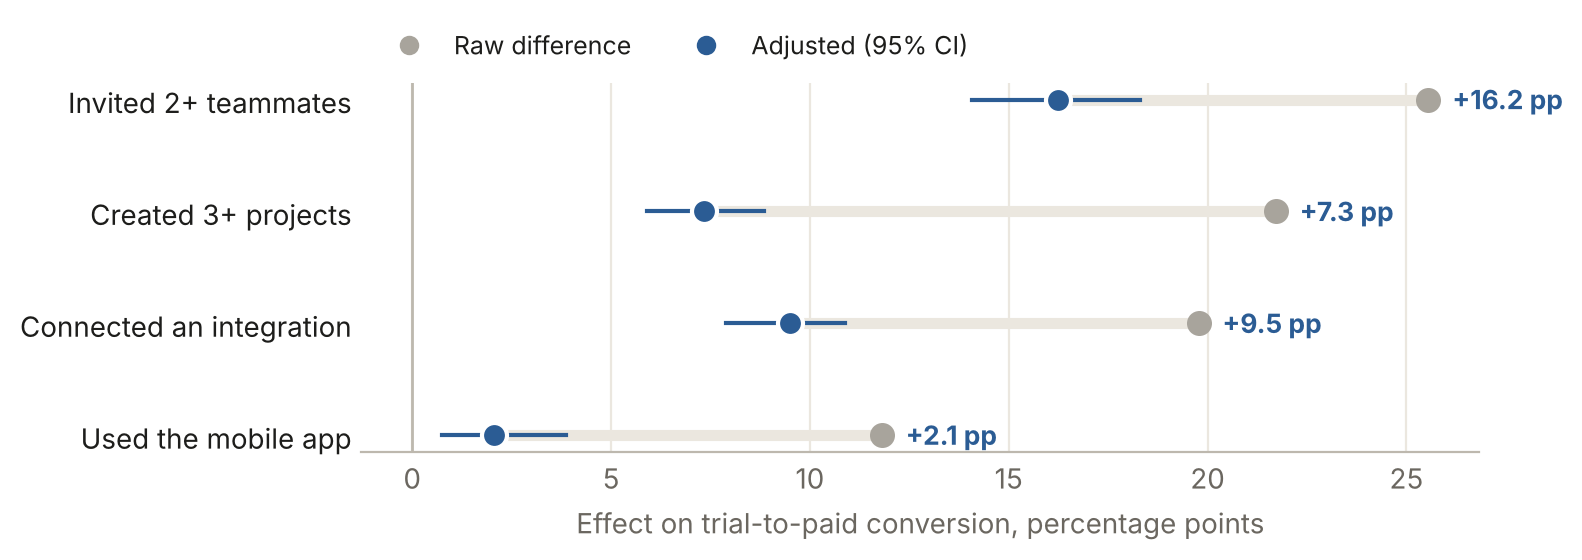

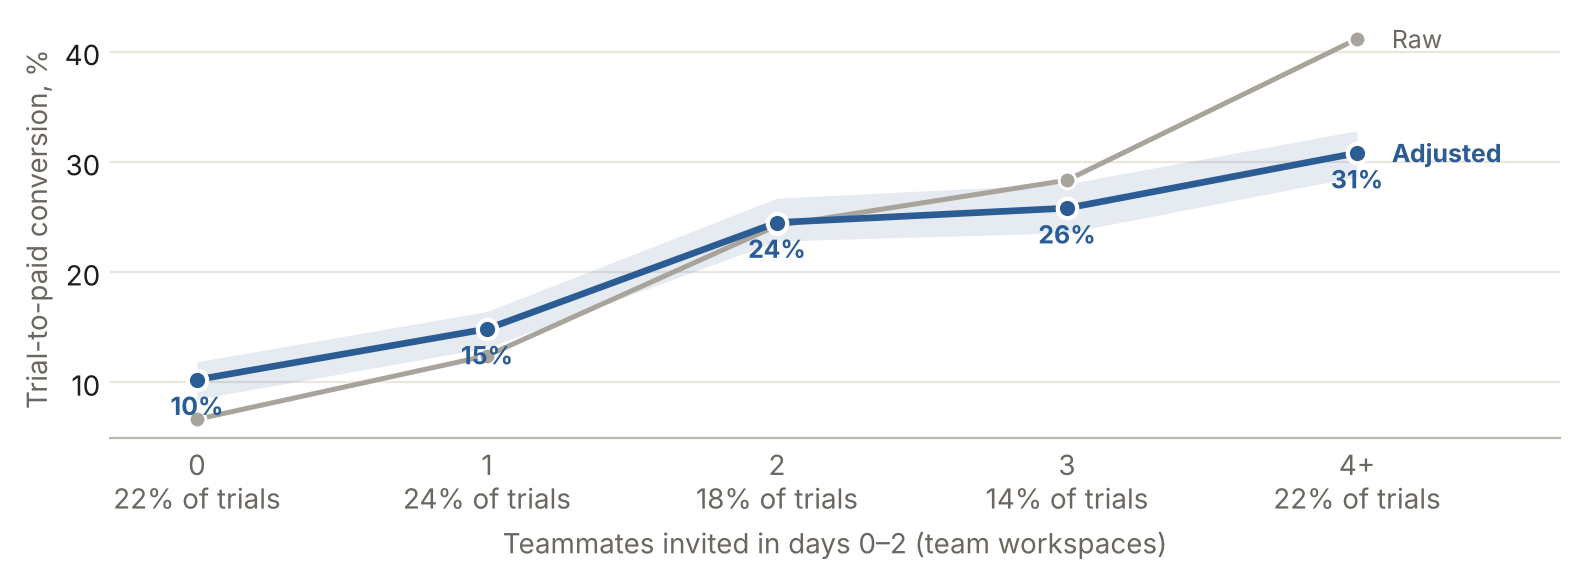

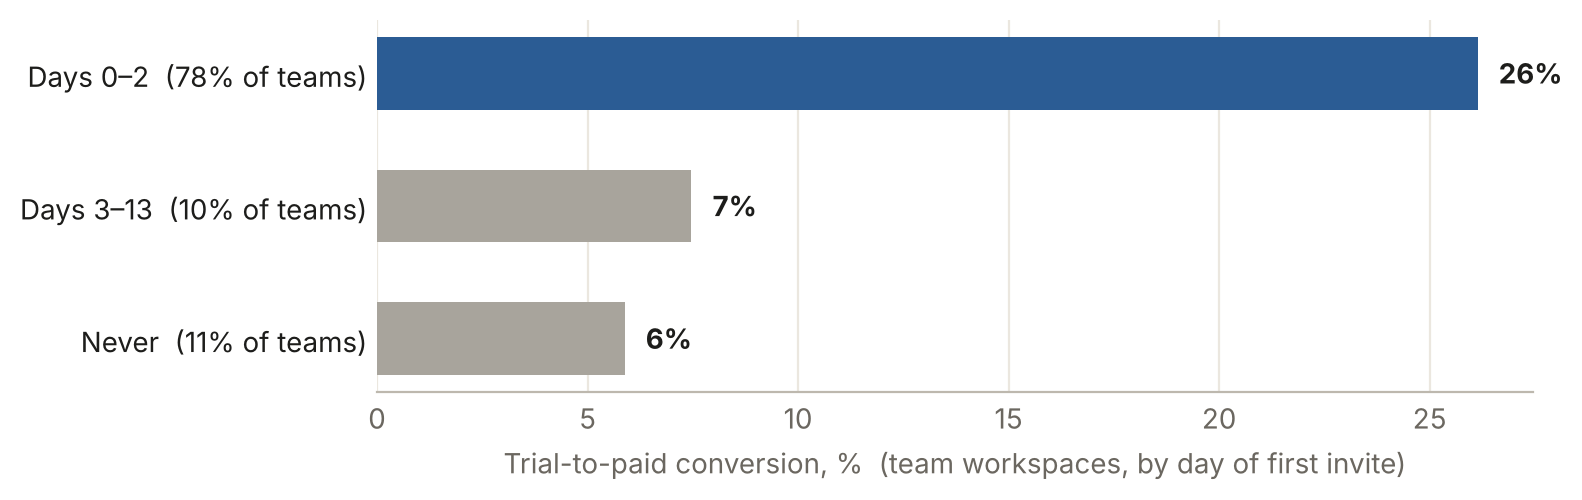

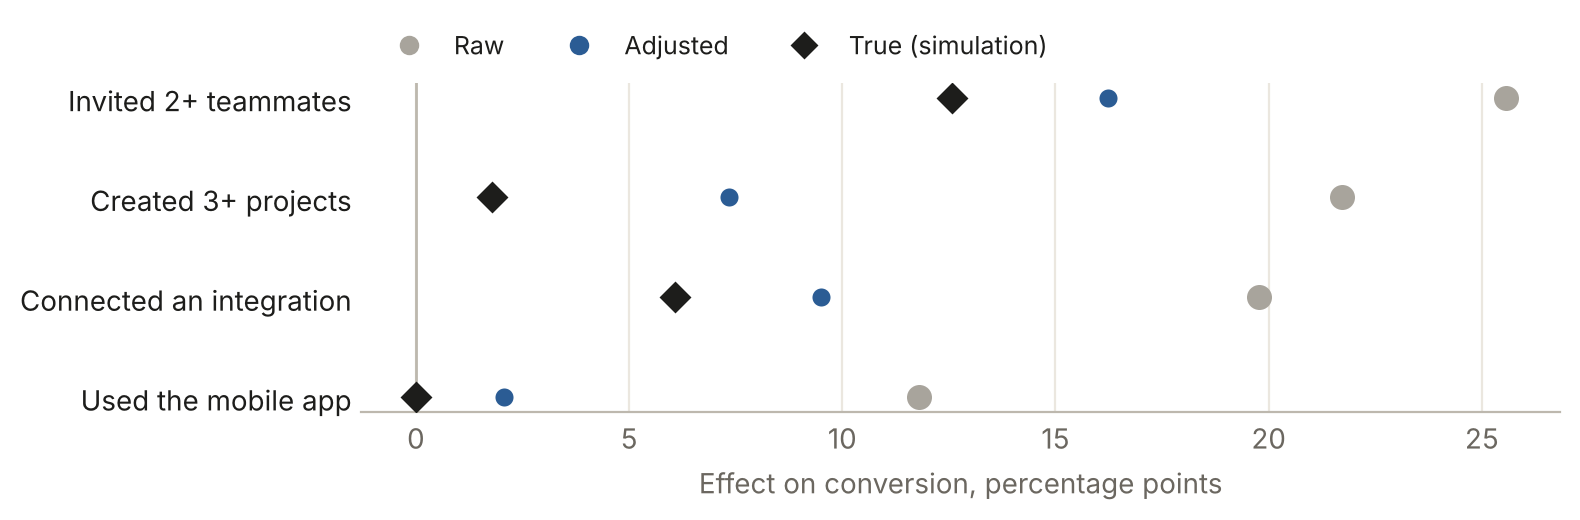

In [9]:
W_, M_, INK, INK2, RULE, GRID, OTHER = "#2b5c94", "#c8693a", "#1d1d1b", "#6b6760", "#bdb8ae", "#ebe7df", "#a8a49c"
plt.rcParams.update({"font.family": "Inter", "font.size": 10, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": RULE, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0, "savefig.transparent": True})

# E1 raw vs adjusted
fig, ax = plt.subplots(figsize=(8, 2.9))
y = np.arange(len(eff))[::-1]
for yi, (lab, r) in zip(y, eff.iterrows()):
    ax.plot([r.adjusted_pp, r.raw_lift_pp], [yi, yi], color=GRID, lw=4, zorder=1)
    ax.plot(r.raw_lift_pp, yi, "o", color=OTHER, ms=8, zorder=3)
    ax.plot([r.lo, r.hi], [yi, yi], color=W_, lw=1.5, zorder=2)
    ax.plot(r.adjusted_pp, yi, "o", color=W_, ms=9, mec="white", mew=1.5, zorder=4)
    ax.text(max(r.raw_lift_pp, r.hi) + .6, yi, f"{r.adjusted_pp:+.1f} pp", va="center", fontsize=9.5, fontweight="bold", color=W_)
ax.axvline(0, color=RULE, lw=1)
ax.set_yticks(y, eff.index); ax.set_xlabel("Effect on trial-to-paid conversion, percentage points")
ax.plot([], [], "o", color=OTHER, label="Raw difference"); ax.plot([], [], "o", color=W_, label="Adjusted (95% CI)")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e1_effects.png", dpi=240)

# E2 threshold: raw vs adjusted
fig, ax = plt.subplots(figsize=(8, 3.0))
x = np.arange(len(thr))
ax.plot(x, thr.conversion * 100, color=OTHER, lw=1.8, marker="o", ms=6, mec="white")
ax.fill_between(x, thr.adj_lo * 100, thr.adj_hi * 100, color=W_, alpha=.12, lw=0)
ax.plot(x, thr.adjusted * 100, color=W_, lw=2.4, marker="o", ms=7, mec="white", mew=1.5)
for xi, (k, r) in zip(x, thr.iterrows()):
    ax.text(xi, r.adjusted * 100 - 3.2, f"{r.adjusted*100:.0f}%", ha="center", fontsize=9, fontweight="bold", color=W_)
ax.text(x[-1] + .12, thr.conversion.iloc[-1] * 100, "Raw", color=INK2, va="center", fontsize=9)
ax.text(x[-1] + .12, thr.adjusted.iloc[-1] * 100, "Adjusted", color=W_, va="center", fontsize=9, fontweight="bold")
ax.set_xticks(x, [f"{k}{'+' if k == '4' else ''}\n{r.share*100:.0f}% of trials" for k, r in thr.iterrows()])
ax.set_xlim(-0.3, len(thr) - 0.3); ax.set_xlabel("Teammates invited in days 0–2 (team workspaces)"); ax.set_ylabel("Trial-to-paid conversion, %")
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e2_threshold.png", dpi=240)

# E3 timing: conversion by when the first invite happened
tm = df[df.team == 1].copy()
tm["when"] = np.select([tm.first_invite_day.between(0, 2), tm.first_invite_day >= 3], ["Days 0–2", "Days 3–13"], "Never")
tt = tm.groupby("when").agg(conversion=("converted", "mean"), share=("converted", "size")).loc[["Days 0–2", "Days 3–13", "Never"]]
tt["share"] /= tt.share.sum()
fig, ax = plt.subplots(figsize=(8, 2.6))
y = np.arange(3)[::-1]
ax.barh(y, tt.conversion * 100, color=[W_, OTHER, OTHER], height=.55)
for yi, (k, r) in zip(y, tt.iterrows()):
    ax.text(r.conversion * 100 + .5, yi, f"{r.conversion*100:.0f}%", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(y, [f"{k}  ({r.share*100:.0f}% of teams)" for k, r in tt.iterrows()])
ax.set_xlabel("Trial-to-paid conversion, %  (team workspaces, by day of first invite)")
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e3_timing.png", dpi=240)

# E4 validation vs truth
fig, ax = plt.subplots(figsize=(8, 2.7))
y = np.arange(len(check))[::-1]
for yi, (lab, r) in zip(y, check.iterrows()):
    ax.plot(r.raw_pp, yi, "o", color=OTHER, ms=8); ax.plot(r.adjusted_pp, yi, "o", color=W_, ms=8, mec="white", mew=1.5)
    ax.plot(r.true_pp, yi, "D", color=INK, ms=7, zorder=4)
ax.plot([], [], "o", color=OTHER, label="Raw"); ax.plot([], [], "o", color=W_, label="Adjusted"); ax.plot([], [], "D", color=INK, label="True (simulation)")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
ax.axvline(0, color=RULE, lw=1); ax.set_yticks(y, check.index); ax.set_xlabel("Effect on conversion, percentage points")
ax.grid(axis="x", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e4_truth.png", dpi=240)
plt.show()

In [10]:
out = dict(n=len(df), conv=df.converted.mean(), raw=raw.to_dict("index"), eff=eff.to_dict("index"), thr=thr.to_dict("index"),
           timing=timing.to_dict(), cum=cum.to_dict(), tt=tt.to_dict("index"), solo=solo_tbl.to_dict("index"), opp=opp, check=check.to_dict("index"),
           team_share=df.team.mean(), inv2_share_team=df[df.team == 1].inv2.mean())
json.dump(out, open("results.json", "w"), default=float, indent=1)